# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 1: Creation and Visualization of Simple Fuzzy Sets**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create and visualize simple fuzzy sets in Python using membership values.

### 2. Theory: Fundamentals of Fuzzy Sets and Membership Grades

In classical set theory (crisp sets), an element $x$ either belongs completely to a set $A$ or does not belong at all. This binary membership is expressed through an indicator function:
$$\chi_A(x) \in \{0, 1\}$$

In contrast, real-world concepts such as *young age*, *tall height*, or *warm weather* are inherently ambiguous and cannot be partitioned by strict numerical cutoffs. Introduced by Lotfi A. Zadeh in 1965, **Fuzzy Set Theory** extends classical sets by assigning each element a degree of membership along a continuous spectrum:
$$\mu_A(x) \in [0, 1]$$
where:
- $\mu_A(x) = 1$ denotes full membership in fuzzy set $A$.
- $\mu_A(x) = 0$ denotes absolute non-membership in fuzzy set $A$.
- $0 < \mu_A(x) < 1$ represents intermediate/partial membership.

#### Key Characteristics of a Fuzzy Set:
1. **Universe of Discourse ($U$):** The complete domain of discourse containing all possible elements under consideration.
2. **Support of $A$:** The crisp set of all elements in $U$ with strictly non-zero membership:
   $$\text{Supp}(A) = \{x \in U \mid \mu_A(x) > 0\}$$
3. **Core of $A$:** The crisp subset of elements possessing complete membership:
   $$\text{Core}(A) = \{x \in U \mid \mu_A(x) = 1\}$$
4. **$\alpha$-Cut ($A_\alpha$):** The crisp subset containing elements whose membership grade is at least $\alpha \in (0, 1]$:
   $$A_\alpha = \{x \in U \mid \mu_A(x) \ge \alpha\}$$

### 3. Step 1: Defining Universe of Discourse and Mathematical Membership Formulations

#### What this cell does:
In this cell, we establish the universe of discourse representing chronological ages $U = \{10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80\}$.
We formulate two distinct fuzzy sets over $U$:
1. $A$ (*"Young"*): Full membership up to age 20, decaying linearly to zero by age 45:
   $$\mu_{\text{Young}}(x) = \begin{cases} 1 & x \le 20 \\ \frac{45 - x}{45 - 20} & 20 < x < 45 \\ 0 & x \ge 45 \end{cases}$$
2. $B$ (*"Middle-Aged"*): Triangular membership centered at age 45, bounded between 25 and 65:
   $$\mu_{\text{Middle}}(x) = \begin{cases} 0 & x \le 25 \\ \frac{x - 25}{45 - 25} & 25 < x \le 45 \\ \frac{65 - x}{65 - 45} & 45 < x < 65 \\ 0 & x \ge 65 \end{cases}$$

In [1]:
import numpy as np

# Define universe of discourse (Ages in years)
universe_ages = np.array([10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80], dtype=float)

def membership_young(age):
    '''Calculates membership grade for fuzzy set Young'''
    if age <= 20:
        return 1.0
    elif 20 < age < 45:
        return (45.0 - age) / (45.0 - 20.0)
    else:
        return 0.0

def membership_middle_aged(age):
    '''Calculates membership grade for fuzzy set Middle-Aged'''
    if age <= 25 or age >= 65:
        return 0.0
    elif 25 < age <= 45:
        return (age - 25.0) / (45.0 - 25.0)
    else:
        return (65.0 - age) / (65.0 - 45.0)

# Vectorized computation of membership values
mu_young = np.array([membership_young(x) for x in universe_ages])
mu_middle = np.array([membership_middle_aged(x) for x in universe_ages])

print("Universe of discourse and fuzzy membership functions defined successfully.")
print(f"Total universe elements: {len(universe_ages)}")


Universe of discourse and fuzzy membership functions defined successfully.
Total universe elements: 15


### 4. Step 2: Tabular Evaluation and $\alpha$-Cut Thresholding

#### What this cell does:
We tabulate the calculated membership grades for each age in the universe and determine the $\alpha$-cut crisp subsets for threshold $\alpha = 0.5$.
$$\text{Young}_{0.5} = \{x \in U \mid \mu_{\text{Young}}(x) \ge 0.5\}$$
$$\text{Middle}_{0.5} = \{x \in U \mid \mu_{\text{Middle}}(x) \ge 0.5\}$$

In [2]:
# Calculate 0.5 alpha-cuts
alpha = 0.5
alpha_cut_young = universe_ages[mu_young >= alpha]
alpha_cut_middle = universe_ages[mu_middle >= alpha]

print("=" * 72)
print("             FUZZY SET MEMBERSHIP GRADES & ANALYSIS TABLE")
print("=" * 72)
print(f"{'Age (x)':<10} | {'mu_Young(x)':<16} | {'mu_Middle(x)':<16} | {'Dominant Class':<18}")
print("-" * 72)

for x, y_val, m_val in zip(universe_ages, mu_young, mu_middle):
    dom = "Young" if y_val > m_val else ("Middle-Aged" if m_val > y_val else "Equally Young/Mid" if y_val > 0 else "Senior")
    print(f"{int(x):<10} | {y_val:<16.3f} | {m_val:<16.3f} | {dom:<18}")

print("=" * 72)
print(f"\nAlpha-cut (alpha = {alpha}):")
print(f"Core(Young)        : {list(universe_ages[mu_young == 1.0])}")
print(f"Supp(Young)        : {list(universe_ages[mu_young > 0.0])}")
print(f"0.5-Cut for Young  : {list(alpha_cut_young)}")
print(f"Core(Middle-Aged)  : {list(universe_ages[mu_middle == 1.0])}")
print(f"Supp(Middle-Aged)  : {list(universe_ages[mu_middle > 0.0])}")
print(f"0.5-Cut for Middle : {list(alpha_cut_middle)}")


             FUZZY SET MEMBERSHIP GRADES & ANALYSIS TABLE
Age (x)    | mu_Young(x)      | mu_Middle(x)     | Dominant Class    
------------------------------------------------------------------------
10         | 1.000            | 0.000            | Young             
15         | 1.000            | 0.000            | Young             
20         | 1.000            | 0.000            | Young             
25         | 0.800            | 0.000            | Young             
30         | 0.600            | 0.250            | Young             
35         | 0.400            | 0.500            | Middle-Aged       
40         | 0.200            | 0.750            | Middle-Aged       
45         | 0.000            | 1.000            | Middle-Aged       
50         | 0.000            | 0.750            | Middle-Aged       
55         | 0.000            | 0.500            | Middle-Aged       
60         | 0.000            | 0.250            | Middle-Aged       
65         | 0.000           

### 5. Step 3: Graphical Visualization of Fuzzy Sets and Alpha-Cuts

#### What this cell does:
We visualize the fuzzy sets using discrete stem markers and smooth interpolated continuous curves, highlighting the transition of membership values and marking the $\alpha = 0.5$ threshold.

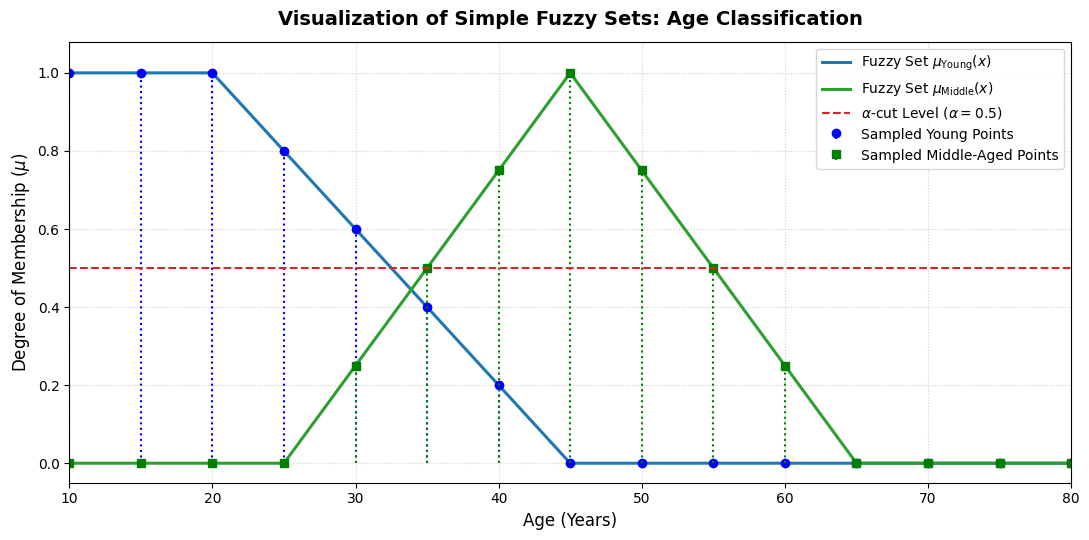

In [3]:
import matplotlib.pyplot as plt

# High-resolution grid for smooth profile curve
fine_x = np.linspace(10, 80, 500)
fine_young = np.array([membership_young(x) for x in fine_x])
fine_middle = np.array([membership_middle_aged(x) for x in fine_x])

plt.figure(figsize=(11, 5.5))

# Plot continuous theoretical profiles
plt.plot(fine_x, fine_young, color='#1f77b4', linestyle='-', linewidth=2.2, label=r'Fuzzy Set $\mu_{\mathrm{Young}}(x)$')
plt.plot(fine_x, fine_middle, color='#2ca02c', linestyle='-', linewidth=2.2, label=r'Fuzzy Set $\mu_{\mathrm{Middle}}(x)$')

# Plot discrete samples
plt.stem(universe_ages, mu_young, linefmt='b:', markerfmt='bo', basefmt=' ', label='Sampled Young Points')
plt.stem(universe_ages, mu_middle, linefmt='g:', markerfmt='gs', basefmt=' ', label='Sampled Middle-Aged Points')

# Draw alpha threshold line
plt.axhline(y=0.5, color='#d62728', linestyle='--', linewidth=1.5, label=r'$\alpha$-cut Level ($\alpha = 0.5$)')

plt.title('Visualization of Simple Fuzzy Sets: Age Classification', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel(r'Degree of Membership ($\mu$)', fontsize=12)
plt.xlim(10, 80)
plt.ylim(-0.05, 1.08)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Age ($x$) | Membership in Young ($\mu_Y$) | Membership in Middle ($\mu_M$) | Boundary Interpretation |
| :---: | :---: | :---: | :--- |
| **10 – 20** | $1.000$ | $0.000$ | Complete member of Young (Core of Young) |
| **25** | $0.800$ | $0.000$ | Highly Young; boundary entry for Middle-Aged |
| **30** | $0.600$ | $0.250$ | Dominantly Young, partial Middle-Aged |
| **32.5** | $0.500$ | $0.375$ | $\alpha = 0.5$ threshold for Young |
| **45** | $0.000$ | $1.000$ | Peak Middle-Aged (Core of Middle) |
| **70 – 80** | $0.000$ | $0.000$ | Outside support of both defined sets |

#### Key Observations in Simple Words:
1. **Gradual Membership Boundaries:** Unlike classical sets where an individual instantaneously stops being young at age 25 or 30, fuzzy logic models the natural gradual fading of youth.
2. **Simultaneous Multi-Set Membership:** At age 30, a person has $\mu_{\text{Young}} = 0.60$ and $\mu_{\text{Middle}} = 0.25$, demonstrating that an element can belong to multiple fuzzy categories at the same time.
3. **Role of $\alpha$-Cuts:** Applying $\alpha = 0.5$ converts the continuous fuzzy concept into an actionable crisp category $\{10, 15, 20, 25, 30\}$ for high-confidence decisions.

---
### 7. Conclusion
1. We successfully created and represented simple fuzzy sets over a discrete and continuous universe of discourse using Python and NumPy.
2. We computed key topological properties of fuzzy sets including Support, Core, and $\alpha$-cuts.
3. We visualized the continuous membership functions and sampled discrete membership grades using dual line and stem plots in Matplotlib.